# Как агент запоминает и исправляет факт о пользователе

Вымышленный пользователь сообщает, в какой день ему удобно получать напоминания. В новом разговоре агент должен вспомнить этот день, а после исправления сохранить новое значение. Сравним, сколько стоят полная история и короткое окно с поиском фактов.

Сначала разберём две сессии локальной Qwen. В конце сравним реальные списания за тот же сценарий на GPT‑4o mini через OpenRouter. Ячейки читают сохранённые результаты обоих прогонов. Их можно повторить с ядром Python 3 и IPython из корня проекта или каталога `hw2`. Живой прогон и его параметры описаны в [README](README.md).

In [1]:
import json
from decimal import Decimal
from pathlib import Path

from IPython.display import Image, Markdown, display

hw2 = Path("hw2") if (Path("hw2") / "results" / "memory").is_dir() else Path(".")
results = hw2 / "results" / "memory"
demo = json.loads((results / "demo.json").read_text(encoding="utf-8"), parse_float=Decimal)
comparison = json.loads((results / "comparison.json").read_text(encoding="utf-8"), parse_float=Decimal)
first, second = demo["sessions"]
turns = [turn for session in (first, second) for turn in session["turns"]]
assert first["session_id"] != second["session_id"]
assert len(turns) >= 10 and len(turns) == len(comparison["turns"])
assert [(s["session_id"], t["question"]) for s in (first, second) for t in s["turns"]] == [
    (t["session_id"], t["question"]) for t in comparison["turns"]
]

def table(headers, rows):
    def line(values):
        return "| " + " | ".join(str(x).replace("|", r"\|").replace("\n", " ") for x in values) + " |"
    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)), *map(line, rows)])))

print(f'Модель: {demo["model"]}. Число предыдущих пар реплик в окне: {demo["window_pairs"]}.')
print(f'Вопросов: {len(first["turns"])} в первой сессии и {len(second["turns"])} во второй.')

Модель: Qwen2.5-1.5B-Instruct-Q4_K_M. Число предыдущих пар реплик в окне: 1.
Вопросов: 6 в первой сессии и 6 во второй.


## Первая сессия. Как реплика становится фактом

Журнал сохраняет реплики с метками сессии и времени. Когда сессия заканчивается, модель извлекает утверждения пользователя. В Milvus у каждого факта есть ключ, значение и сессия, где он был сохранён. В таблице можно сопоставить извлечённый факт с исходной репликой.

In [2]:
def by_key(session):
    facts = session["facts_after"]
    unique = {fact["key"]: fact["value"] for fact in facts}
    assert len(unique) == len(facts), "В памяти несколько записей с одним ключом"
    return unique

before = by_key(first)
after = by_key(second)
changed = [key for key in before.keys() & after.keys() if before[key] != after[key]]
reminder, = [key for key in changed if "tuesday" in before[key].casefold() and "friday" in after[key].casefold()]
for session in (first, second):
    utterances = [t["question"] for t in session["turns"]]
    assert all(any(f["evidence"] in u for u in utterances) for f in session["extracted"])

table(["Ключ", "Сохранённое значение", "Слова пользователя из первой сессии"],
      [(f["key"], before[f["key"]], f["evidence"]) for f in first["extracted"]])
example = next((t for t in first["turns"] if "knowledge_base" in t["tool_calls"]), first["turns"][0])
print(f'Пример вопроса в первой сессии: {example["question"]}')
print(f'Ответ агента: {example["answer"]}')
if example["tool_calls"]:
    print("Вызванные инструменты:", ", ".join(example["tool_calls"]))

| Ключ | Сохранённое значение | Слова пользователя из первой сессии |
| --- | --- | --- |
| reminder_day | Tuesday | I prefer Tuesday for reminders. |
| distance_unit | kilometers | I use kilometers for distances. |

Пример вопроса в первой сессии: Use the knowledge_base tool to look up the number of job cuts Statistics Canada announced on January 13, 2026.
Ответ агента: unknown
Вызванные инструменты: knowledge_base


## Новый разговор. Откуда взялся ответ

Посмотрим на первый вопрос второй сессии. Здесь видны три разные вещи — сколько реплик попало в короткое окно, какие факты вернул поиск и что ответила модель. У найденного факта должен быть тот же ключ и то же значение, что и после первой сессии.

In [3]:
window_size = 2 * demo["window_pairs"]
for session in (first, second):
    session_messages = []
    for turn in session["turns"]:
        previous = session_messages[-window_size:] if window_size else []
        assert turn["history"] == previous, "Окно расходится с репликами текущей сессии"
        session_messages.extend([{"role": "user", "content": turn["question"]},
                                 {"role": "assistant", "content": turn["answer"]}])
opening = second["turns"][0]
assert opening["history"] == [] and "tuesday" not in opening["question"].casefold()
hits = opening["facts"]
assert any(f["key"] == reminder and f["value"] == before[reminder] and
           f["session_id"] == first["session_id"] for f in hits)
assert "tuesday" in opening["answer"].casefold()

print(f'Пользователь: {opening["question"]}')
print(f'Предыдущих сообщений в окне: {len(opening["history"])}')
table(["Ключ из Milvus", "Значение", "Из сессии"],
      [(f["key"], f["value"], f["session_id"]) for f in hits])
print(f'Ответ агента: {opening["answer"]}')

Пользователь: What is my preferred reminder day? Reply with just the weekday.
Предыдущих сообщений в окне: 0


| Ключ из Milvus | Значение | Из сессии |
| --- | --- | --- |
| reminder_day | Tuesday | session-1 |
| distance_unit | kilometers | session-1 |

Ответ агента: Tuesday


## Исправление дня напоминания

После второй сессии найдём тот же ключ в памяти и проверим, что у него осталось ровно одно действующее значение. В таблице приведены оба снимка и фраза пользователя, на которой основана запись.

In [4]:
changes = []
for s in (first, second):
    fact, = [f for f in s["facts_after"] if f["key"] == reminder]
    extraction, = [f for f in s["extracted"] if f["key"] == reminder]
    assert fact["session_id"] == s["session_id"] and fact["value"] == extraction["value"]
    changes.append((s["session_id"], fact["key"], fact["value"], extraction["evidence"]))
table(["Снимок", "Ключ", "Единственное действующее значение", "Подтверждение пользователя"], changes)
current, = [f for f in demo["final_lookup"] if f["key"] == reminder]
assert current["value"] == after[reminder] and current["session_id"] == second["session_id"]
last = second["turns"][-1]
print(f'Последний вопрос до сохранения: {last["question"]}')
print(f'Ответ с коротким окном: {last["answer"]}')
print(f'Повторный поиск после записи в Milvus: {current["key"]} → {current["value"]}')

| Снимок | Ключ | Единственное действующее значение | Подтверждение пользователя |
| --- | --- | --- | --- |
| session-1 | reminder_day | Tuesday | I prefer Tuesday for reminders. |
| session-2 | reminder_day | Friday | I now prefer Friday for reminders. |

Последний вопрос до сохранения: Write the weekday from my most recent correction, with no extra words.
Ответ с коротким окном: Tuesday
Повторный поиск после записи в Milvus: reminder_day → Friday


На последнем вопросе второй сессии агент ответил *Tuesday*. К этому моменту исправление вышло из окна в одну пару реплик, а поиск ещё возвращал старое значение. Обновление в конце сессии записало *Friday*. Значит, в таком коротком окне агент может пропустить исправление до ближайшего сохранения.

## Сколько контекста получает модель

Одна точка на графике соответствует одному вопросу пользователя. В полной истории доступны предыдущие реплики, включая первую сессию. В оба режима подают один и тот же диалог — предыдущие ответы берутся из режима с окном. Во втором режиме модель получает недавние реплики только текущей сессии и найденные в Milvus факты. Расходы на извлечение фактов в конце сессий посчитаны отдельно в следующей ячейке.

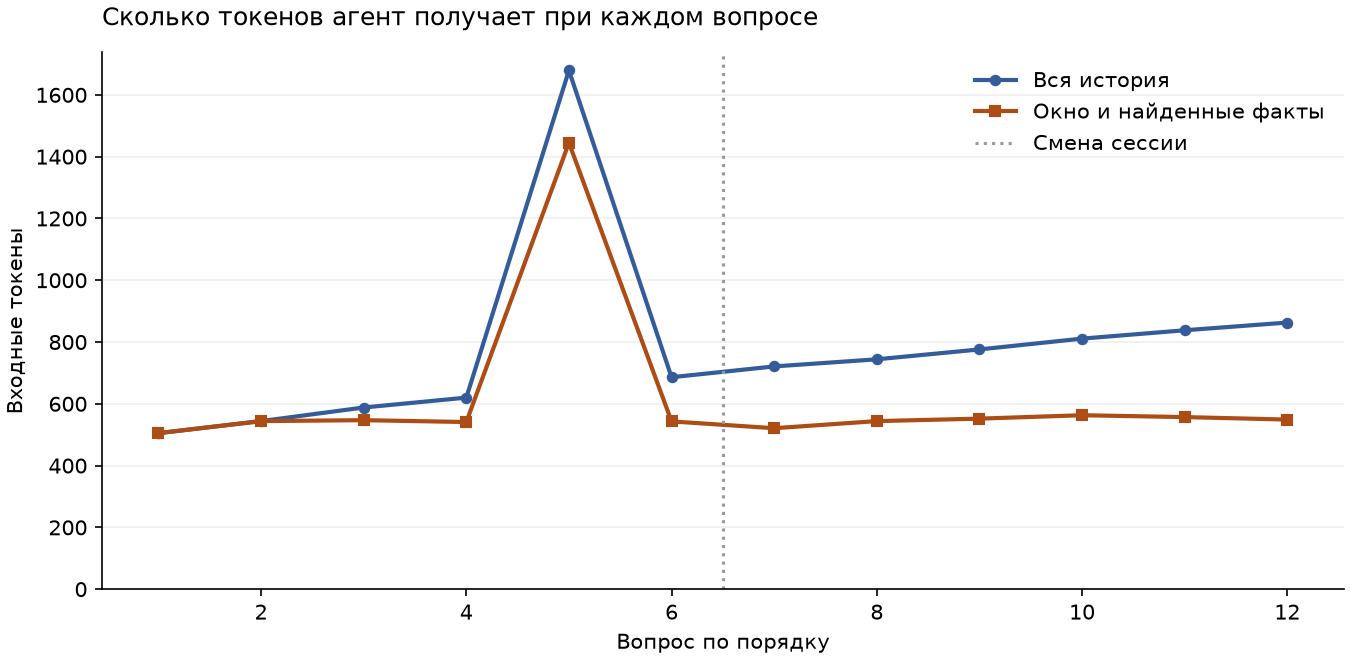

In [5]:
display(Image(filename=str(results / "input_tokens.png"), width=830))

## Цена диалога вместе с сохранением памяти

Проверим таблицу суммированием токенов и расходов всех шагов. У режима с памятью есть два вида затрат — ответы в диалоге и вызовы модели в конце сессий. Обе составляющие входят в его итог.

In [6]:
def verified_totals(run, report):
    totals = report["totals"]
    turns = [turn for session in run["sessions"] for turn in session["turns"]]
    fields = ("prompt_tokens", "completion_tokens", "cost_usd")
    for turn, measured_turn in zip(turns, report["turns"], strict=True):
        for mode, receipts in (("full", turn["full_receipts"]), ("window", turn["receipts"])):
            assert receipts and all(r["request_id"] for r in receipts)
            for field in fields:
                from_receipts = sum(r[field] for r in receipts)
                assert abs(from_receipts - measured_turn[mode][field]) <= Decimal("0.000000001")
    for session, record in zip(run["sessions"], report["extractions"], strict=True):
        assert record["session_id"] == session["session_id"]
        assert all(record[field] == session["extraction_usage"][field] for field in fields)

    groups = {
        "full": [t["full"] for t in report["turns"]],
        "window_answers": [t["window"] for t in report["turns"]],
        "extractions": report["extractions"],
    }
    groups["window"] = groups["window_answers"] + groups["extractions"]
    for mode, records in groups.items():
        for field in fields:
            measured = sum(Decimal(str(record[field])) for record in records)
            recorded = Decimal(str(totals[mode][field]))
            assert abs(measured - recorded) <= Decimal("0.000000001"), (mode, field, measured, recorded)

    return totals

totals = verified_totals(demo, comparison)
labels = {"full": "Вся история, итого", "window_answers": "Окно и факты, ответы",
          "extractions": "Извлечение фактов", "window": "Окно и факты, итого"}
table(["Режим", "Входные токены", "Выходные токены", "Списано, USD"],
      [(label, totals[key]["prompt_tokens"], totals[key]["completion_tokens"],
        f'{totals[key]["cost_usd"]:.8f}') for key, label in labels.items()])
full, window = totals["full"], totals["window"]
tokens_saved = 100 * (1 - Decimal(window["prompt_tokens"]) / full["prompt_tokens"])
print(f'С учётом извлечения модель получила на {tokens_saved:.1f}% меньше входных токенов.')
print(f'Источник цен: {comparison["price_basis"]}.')
if full["cost_usd"] > 0:
    saving = 100 * (1 - window["cost_usd"] / full["cost_usd"])
    print(f'Изменение цены при переходе к памяти: {-saving:+.1f}%.')
else:
    print("Оба режима выполнялись локально. Денежное сравнение ограничено списаниями API.")
if "hypothetical_pricing" in comparison:
    rates = comparison["hypothetical_pricing"]
    print(f'Условная оценка при ставках {rates["usd_per_million_input_tokens"]} USD за миллион входных '
          f'и {rates["usd_per_million_output_tokens"]} USD за миллион выходных токенов:')
    for mode in ("full", "window"):
        print(f'  {labels[mode]}: {rates["estimated_usd"][mode]:.8f} USD')
    estimate = rates["estimated_usd"]
    print(f'При этих ставках расчётная экономия составляет {100 * (1 - estimate["window"] / estimate["full"]):.1f}%.')

| Режим | Входные токены | Выходные токены | Списано, USD |
| --- | --- | --- | --- |
| Вся история, итого | 9375 | 152 | 0.00000000 |
| Окно и факты, ответы | 7411 | 110 | 0.00000000 |
| Извлечение фактов | 262 | 31 | 0.00000000 |
| Окно и факты, итого | 7673 | 141 | 0.00000000 |

С учётом извлечения модель получила на 18.2% меньше входных токенов.
Источник цен: Local CPU, API charges.
Оба режима выполнялись локально. Денежное сравнение ограничено списаниями API.
Условная оценка при ставках 0.15 USD за миллион входных и 0.6 USD за миллион выходных токенов:
  Вся история, итого: 0.00149745 USD
  Окно и факты, итого: 0.00123555 USD
При этих ставках расчётная экономия составляет 17.5%.


## Сколько стоил тот же диалог на GPT‑4o mini

Оба режима получили те же 12 вопросов в том же порядке. Каждая строка ниже использует списания `usage.cost` из квитанций OpenRouter. В итог окна входят ответы и оба извлечения фактов. [График входных токенов GPT‑4o mini по вопросам](results/memory/openrouter/input_tokens.png).

In [7]:
paid_dir = results / "openrouter"
paid_demo = json.loads((paid_dir / "demo.json").read_text(encoding="utf-8"), parse_float=Decimal)
paid_report = json.loads((paid_dir / "comparison.json").read_text(encoding="utf-8"), parse_float=Decimal)
assert paid_demo["model"] == paid_report["model"] == "openai/gpt-4o-mini"
assert paid_report["price_basis"] == "OpenRouter usage.cost"
scenario = [(t["session_id"], t["question"]) for t in comparison["turns"]]
assert scenario == [(s["session_id"], t["question"]) for s in paid_demo["sessions"] for t in s["turns"]]
assert scenario == [(t["session_id"], t["question"]) for t in paid_report["turns"]]
paid_totals = verified_totals(paid_demo, paid_report)
table(["Режим", "Входные токены", "Выходные токены", "Списано OpenRouter, USD"],
      [(name, paid_totals[k]["prompt_tokens"], paid_totals[k]["completion_tokens"],
        f'{paid_totals[k]["cost_usd"]:.8f}') for k, name in labels.items()])
full_cost = paid_totals["full"]["cost_usd"]
memory_cost = paid_totals["window"]["cost_usd"]
assert full_cost > 0 and memory_cost > 0
print(f"Изменение цены с памятью относительно полной истории: {100 * (memory_cost / full_cost - 1):+.1f}%.")
print(f"Сумма списаний за оба режима: {full_cost + memory_cost:.8f} USD.")

| Режим | Входные токены | Выходные токены | Списано OpenRouter, USD |
| --- | --- | --- | --- |
| Вся история, итого | 7562 | 87 | 0.00118650 |
| Окно и факты, ответы | 6750 | 106 | 0.00107610 |
| Извлечение фактов | 261 | 33 | 0.00005895 |
| Окно и факты, итого | 7011 | 139 | 0.00113505 |

Изменение цены с памятью относительно полной истории: -4.3%.
Сумма списаний за оба режима: 0.00232155 USD.


In [8]:
paid_first, paid_second = paid_demo["sessions"]
start_day = by_key(paid_first)[reminder]
finish_day = by_key(paid_second)[reminder]
stored_day, = [f for f in paid_demo["final_lookup"] if f["key"] == reminder]
assert stored_day["value"] == finish_day and stored_day["session_id"] == paid_second["session_id"]
assert start_day.casefold() == "tuesday" and finish_day.casefold() == "friday"
begin, *_, end = paid_second["turns"]
change, = [t for t in paid_second["turns"] if "I now prefer" in t["question"]]
assert begin["history"] == [] and any(f["key"] == reminder and f["value"] == start_day for f in begin["facts"])
table(["Момент второй сессии", "Вопрос пользователя", "Вся история", "Окно и факты"],
      [(label, t["question"], t["full_answer"], t["answer"]) for label, t in [
          ("Первый вопрос о напоминании", begin), ("Пользователь меняет день", change),
          ("Последний вопрос перед сохранением", end)]])
print(f'В Milvus после первой сессии — {start_day}. После обновления — {stored_day["value"]}.')

| Момент второй сессии | Вопрос пользователя | Вся история | Окно и факты |
| --- | --- | --- | --- |
| Первый вопрос о напоминании | What is my preferred reminder day? Reply with just the weekday. | Tuesday | Tuesday |
| Пользователь меняет день | I have changed my preference. I now prefer Friday for reminders. Which day should you use from now on? | Friday | Friday |
| Последний вопрос перед сохранением | Write the weekday from my most recent correction, with no extra words. | Friday | Tuesday |

В Milvus после первой сессии — Tuesday. После обновления — Friday.
